# BlindCore Homomorphic Compute Demo: Pure Client-Side Zero-Knowledge Blind OLAP & Blind Ridge

> **Security & Threat-Model Disclosure (External Cryptographic Audit)**
>
> | Deployment Mode | Endpoints Used | Key Custody | What the Server Sees |
> | :--- | :--- | :--- | :--- |
> | **Mode 1 -- Unencrypted / TLS SQL Engine** | `/api/v1/query` | Transport TLS only (no client FHE) | Plaintext SQL inputs & results in server memory (Section 6 baseline only: SQL plaintext oracle for head-to-head comparison) |
> | **Mode 2 -- Pure Client-Side Encrypted (Zero-Knowledge)** | `/api/v1/blind/*`, `/api/v1/blind/jsonb/*` | **100% Client-Side** (`BlindClientPlweKey` + `BlindClientEnvelopeKey`) | **0 plaintext, 0 keys, 0 `seal_*`, 0 `threshold_decrypt`, 0 `decrypted_aggregate`** (Sections 1-6: 100% pure client-side Blind OLAP + Blind Ridge training & inference) |
>
> In Mode 2 every integer leaves the client as an `80 B` IND-CPA `PLWE0001` ciphertext (`205.8x` smaller on ingress than the `16,464 B` expanded homomorphic output frame), small-cardinality class indicators are encoded as IND-CPA `PLWE0001` `{0, 1}` / `{0, v}` columns summed unconditionally over all rows (preventing row-partition frequency analysis), high-cardinality exact-match handles use keyed `32 B` HMAC-SHA256 tokens (disclosing exact-match equality only, with fixed dummy-padded slots hiding arity), and payloads are sealed in `SBLB0001` (`PAD2 + AES-256-GCM`, `{64..4096}` buckets hiding length). Only the client verifies `NSAU0001` SHA-256 receipts and decrypts aggregate ciphertexts locally.

> **Why `seal_values` & `threshold_decrypt` Are Omitted:** Server-assisted sealing (`seal_values`) and server-side threshold decryption (`threshold_decrypt`) are convenience demo endpoints where the server handles plaintext during ingest or decryption. Every homomorphic computation in this notebook runs strictly in **Mode 2**: `100%` client-side `BlindClientPlweKey` + `BlindClientEnvelopeKey`, `0` `seal_values`, `0` `threshold_decrypt`, and `0` `decrypted_aggregate` on the wire.

---

**Target Markets:** Healthcare (HIPAA), Financial Services, Defense & Multi-Party Analytics.
**Workflow:** Encrypt hospital claims and clinical Ridge sufficient statistics strictly on the client into `80 B` IND-CPA `PLWE0001` frames and `SBLB0001` AEAD envelopes -> execute blind homomorphic `SUM`, `ADD`, `SUB`, `WEIGHTED_SUM`, and blind `Ridge` training/inference on live BlindCore -> verify `NSAU0001` SHA-256 receipts + raw wire zero-plaintext audit -> decrypt strictly on the client.

In [1]:
import collections
import hashlib
import hmac
import http.server
import json
import math
import os
import secrets
import struct
import sys
import threading
import time
import urllib.error
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import Ridge

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.facecolor"] = "white"

REPO_ROOT = Path.cwd().resolve()
if not (
    (REPO_ROOT / "python" / "blindcore_sdk.py").is_file()
    or (REPO_ROOT / "python" / "blindcore_client.py").is_file()
):
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT / "python") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "python"))

try:
    from blindcore_sdk import (
        BlindClientEnvelopeKey,
        BlindClientPlweKey,
        BlindCoreClient,
        PLWE_EXPANDED_BYTES,
        PLWE_SEEDED_BYTES,
    )
except ImportError:
    from blindcore_client import (
        BlindClientEnvelopeKey,
        BlindClientPlweKey,
        BlindCoreClient,
        PLWE_EXPANDED_BYTES,
        PLWE_SEEDED_BYTES,
    )

BLINDCORE_URL = os.environ["BLINDCORE_URL"].strip()
BLINDCORE_TOKEN = os.environ["BLINDCORE_TOKEN"].strip()
assert BLINDCORE_URL and BLINDCORE_TOKEN, "Set BLINDCORE_URL and BLINDCORE_TOKEN env vars"


class WireSniffProxy:
    """Transparent localhost pass-through proxy capturing raw Mode 2 HTTP request & response bytes."""

    def __init__(self, upstream: str) -> None:
        self.upstream = upstream.rstrip("/")
        self.req_bytes: list[bytes] = []
        self.resp_bytes: list[bytes] = []
        self._lock = threading.Lock()
        outer = self

        class _H(http.server.BaseHTTPRequestHandler):
            def log_message(self, fmt: str, *args: object) -> None:
                return

            def _fwd(self, method: str) -> None:
                n = int(self.headers.get("Content-Length", "0"))
                body = self.rfile.read(n) if n > 0 else b""
                with outer._lock:
                    outer.req_bytes.append(body)
                hdrs = {k: self.headers[k] for k in ("Authorization", "Content-Type", "Accept") if k in self.headers}
                req = urllib.request.Request(f"{outer.upstream}{self.path}", data=body if method != "GET" else None, headers=hdrs, method=method)
                try:
                    with urllib.request.urlopen(req, timeout=30.0) as r:
                        raw, st, ct = r.read(), r.status, r.headers.get("Content-Type", "application/json")
                except urllib.error.HTTPError as exc:
                    raw, st, ct = exc.read(), int(exc.code), exc.headers.get("Content-Type", "application/json")
                with outer._lock:
                    outer.resp_bytes.append(raw)
                self.send_response(st)
                self.send_header("Content-Type", ct)
                self.send_header("Content-Length", str(len(raw)))
                self.end_headers()
                self.wfile.write(raw)

            def do_GET(self) -> None:
                self._fwd("GET")

            def do_POST(self) -> None:
                self._fwd("POST")

        self.srv = http.server.ThreadingHTTPServer(("127.0.0.1", 0), _H)
        self.url = f"http://127.0.0.1:{self.srv.server_address[1]}"
        self._th = threading.Thread(target=self.srv.serve_forever, daemon=True)
        self._th.start()

    def close(self) -> None:
        self.srv.shutdown()
        self.srv.server_close()


def verify_nsau0001_table_receipt(table: str, col_count: int, resp: dict) -> tuple[bool, str]:
    if resp.get("receipt_magic") != "NSAU0001":
        return False, ""
    pre = b"NSAU0001:BLIND:TABLE:" + table.encode("ascii") + struct.pack("<Q", int(col_count))
    loc = hashlib.sha256(pre).hexdigest()
    return hmac.compare_digest(loc, str(resp.get("receipt_hex", ""))), loc


def verify_nsau0001_query_receipt(resp: dict) -> tuple[bool, str]:
    if resp.get("receipt_magic") != "NSAU0001":
        return False, ""
    pre = (
        b"NSAU0001:BLIND:"
        + str(resp["op"]).encode("ascii")
        + b":"
        + str(resp["table"]).encode("ascii")
        + struct.pack("<Q", int(resp["rows_scanned"]))
        + bytes.fromhex(str(resp["ct_result_hex"]))
    )
    loc = hashlib.sha256(pre).hexdigest()
    return hmac.compare_digest(loc, str(resp.get("receipt_hex", ""))), loc


def shannon_entropy_plwe_var(pk: BlindClientPlweKey, n_samples: int = 256) -> float:
    blob = b"".join((ct[40:56] + ct[60:80]) for ct in (pk.encrypt_int(42) for _ in range(n_samples)))
    cnts = collections.Counter(blob)
    n = len(blob)
    return -sum((c / n) * math.log2(c / n) for c in cnts.values()) if n else 0.0


def flip_hex_lsb(h: str) -> str:
    b = bytearray.fromhex(h)
    b[-1] ^= 0x01
    return b.hex()


client = BlindCoreClient(BLINDCORE_URL, BLINDCORE_TOKEN, timeout=30.0)
t0_hb = time.perf_counter()
hb = client.query_json("SELECT 1 AS ok")
hb_rtt_ms = (time.perf_counter() - t0_hb) * 1000.0
assert hb["rows"] == [[1]]
print(f"Heartbeat: OK | HTTP RTT={hb_rtt_ms:.2f} ms | Rust engine={int(hb.get('elapsed_us', 0))} us")

Heartbeat: OK | HTTP RTT=0.69 ms | Rust engine=23 us


## 1. Pure Client-Side Blind OLAP Schema (`POST /api/v1/blind/table`)

We generate fresh client-only keys (`BlindClientPlweKey` + `BlindClientEnvelopeKey`) that **never leave this notebook process**, declare a timestamped Blind OLAP table using only ciphertext column kinds (`blind_token` for high-cardinality record handles, `blind_add` for `80 B` IND-CPA `PLWE0001` numeric values & `{0,1}`/`{0,v}` class indicators, and `sealed_blob` for `SBLB0001` patient notes), and verify the `NSAU0001` table creation receipt.

In [2]:
pk = BlindClientPlweKey.generate()
ek = BlindClientEnvelopeKey.generate()

# Verify IND-CPA randomness and variable-byte Shannon entropy (> 7.95 bits/B)
c_a = pk.encrypt_int(42)
c_b = pk.encrypt_int(42)
assert len(c_a) == PLWE_SEEDED_BYTES and c_a != c_b, "IND-CPA non-determinism failed"
ent_bits = shannon_entropy_plwe_var(pk, n_samples=256)
assert ent_bits > 7.95, f"Entropy below threshold: {ent_bits:.4f}"

TABLE_NAME = f"blind_m2_hospital_{secrets.token_hex(4)}"
SCHEMA_COLUMNS = [
    {"name": "patient_handle_tok", "kind": "blind_token"},
    {"name": "claim_usd", "kind": "blind_add"},
    {"name": "adjustment_usd", "kind": "blind_add"},
    {"name": "high_acuity_flag", "kind": "blind_add"},
    {"name": "high_acuity_claim", "kind": "blind_add"},
    {"name": "record_envelope", "kind": "sealed_blob"},
]

sniffer = WireSniffProxy(BLINDCORE_URL)
zk_client = BlindCoreClient(sniffer.url, BLINDCORE_TOKEN, timeout=30.0)

t0 = time.perf_counter()
create_res = zk_client.create_blind_table(TABLE_NAME, SCHEMA_COLUMNS)
create_rtt_ms = (time.perf_counter() - t0) * 1000.0

assert create_res.get("status") == "ok" and create_res.get("plaintext_stored") is False
tbl_ok, tbl_hex = verify_nsau0001_table_receipt(TABLE_NAME, len(SCHEMA_COLUMNS), create_res)
assert tbl_ok
bad_tbl = dict(create_res)
bad_tbl["receipt_hex"] = flip_hex_lsb(create_res["receipt_hex"])
assert not verify_nsau0001_table_receipt(TABLE_NAME, len(SCHEMA_COLUMNS), bad_tbl)[0]

receipt_audit_log = [("CREATE TABLE", TABLE_NAME, len(SCHEMA_COLUMNS), create_res["receipt_magic"], tbl_hex, True)]
print(f"Created Mode 2 Blind Table : {TABLE_NAME} ({len(SCHEMA_COLUMNS)} ciphertext columns, 0 plain columns)")
print(f"Client Key Custody         : 100% local | IND-CPA ct1!=ct2=PASS | Entropy={ent_bits:.4f} bits/B")
print(f"NSAU0001 Table Receipt     : {tbl_hex[:24]}... (verified=True, 1-bit flip rejected=True, {create_rtt_ms:.2f} ms)")

Created Mode 2 Blind Table : blind_m2_hospital_7faf40e1 (6 ciphertext columns, 0 plain columns)
Client Key Custody         : 100% local | IND-CPA ct1!=ct2=PASS | Entropy=7.9796 bits/B
NSAU0001 Table Receipt     : df4ab24ebdfa15865661c860... (verified=True, 1-bit flip rejected=True, 66.12 ms)


## 2. Client-Side Encryption, Zero-Plaintext Wire Audit & Raw Storage Inspection

Every synthetic hospital claim is encrypted locally via `pk.encrypt_int_hex(...)` and `ek.seal_json_hex(...)` and sent strictly under ``ciphertexts_hex`` -- **never** ``seal_values``. We then inspect both the raw captured HTTP wire bytes and the server's underlying SQL storage (`SELECT * LIMIT 3`) to prove `0` plaintext leakage in transit or at rest.

In [3]:
COHORT_ROWS = [
    {"id": "pt_101", "claim_usd": 184500, "adjustment_usd": -12500, "high_acuity": 1, "note": "CANARY_HOSP_CLAIM_101"},
    {"id": "pt_102", "claim_usd": 249000, "adjustment_usd":  18200, "high_acuity": 1, "note": "CANARY_HOSP_CLAIM_102"},
    {"id": "pt_103", "claim_usd":  96400, "adjustment_usd":  -8400, "high_acuity": 0, "note": "CANARY_HOSP_CLAIM_103"},
    {"id": "pt_104", "claim_usd": 312800, "adjustment_usd": -24600, "high_acuity": 1, "note": "CANARY_HOSP_CLAIM_104"},
    {"id": "pt_105", "claim_usd": 158300, "adjustment_usd":   9100, "high_acuity": 0, "note": "CANARY_HOSP_CLAIM_105"},
    {"id": "pt_106", "claim_usd": 219000, "adjustment_usd": -11800, "high_acuity": 0, "note": "CANARY_HOSP_CLAIM_106"},
]

t0_enc = time.perf_counter()
encrypted_rows = [
    {
        "ciphertexts_hex": {
            "patient_handle_tok": ek.blind_token_hex("patient_id", r["id"]),
            "claim_usd": pk.encrypt_int_hex(r["claim_usd"]),
            "adjustment_usd": pk.encrypt_int_hex(r["adjustment_usd"]),
            "high_acuity_flag": pk.encrypt_int_hex(r["high_acuity"]),
            "high_acuity_claim": pk.encrypt_int_hex(r["claim_usd"] if r["high_acuity"] else 0),
            "record_envelope": ek.seal_json_hex({"id": r["id"], "note": r["note"]}, aad=r["id"].encode("ascii")),
        }
    }
    for r in COHORT_ROWS
]
enc_ms = (time.perf_counter() - t0_enc) * 1000.0
assert len(bytes.fromhex(encrypted_rows[0]["ciphertexts_hex"]["claim_usd"])) == PLWE_SEEDED_BYTES

t0_ing = time.perf_counter()
ingest_res = zk_client.ingest_blind(TABLE_NAME, encrypted_rows)
ing_ms = (time.perf_counter() - t0_ing) * 1000.0
assert ingest_res.get("status") == "ok" and int(ingest_res.get("rows_ingested", 0)) == len(COHORT_ROWS)

raw_sql = client.query_json(f"SELECT * FROM {TABLE_NAME} LIMIT 3")
assert len(raw_sql["rows"]) == 3
storage_dump = json.dumps(raw_sql["rows"])
wire_dump = b"\n".join(sniffer.req_bytes + sniffer.resp_bytes)

for secret_str in ["184500", "249000", "312800", "CANARY_HOSP_CLAIM_101", "pt_101", "seal_values", "threshold_decrypt"]:
    assert secret_str not in storage_dump, f"Storage leaked {secret_str}!"
    assert secret_str.encode("ascii") not in wire_dump, f"Wire leaked {secret_str}!"

print(f"Client Encrypt ({len(COHORT_ROWS)} rows) : {enc_ms:.2f} ms | Server Blind Ingest: {ing_ms:.2f} ms")
print(f"Raw Wire Audit          : 0 plaintext leaks across {len(wire_dump):,} captured HTTP bytes")
print(f"Raw SQL SELECT * LIMIT 3: 0 plaintext leaks (claim_usd sample: {str(raw_sql['rows'][0][raw_sql['columns'].index('claim_usd')])[:32]}...)")

Client Encrypt (6 rows) : 7.04 ms | Server Blind Ingest: 2.27 ms
Raw Wire Audit          : 0 plaintext leaks across 7,544 captured HTTP bytes
Raw SQL SELECT * LIMIT 3: 0 plaintext leaks (claim_usd sample: 504c5745303030310100000101000000...)


## 3. Pure Client-Side Blind Homomorphic OLAP (`0` Server Keys, `0` `threshold_decrypt`)

Every homomorphic query below omits `threshold_decrypt`, asserts ``decrypted_aggregate`` is absent from the server response, validates the `16,464 B` expanded `PLWE0001` frame and `NSAU0001` SHA-256 receipt (including 1-bit tamper rejection), decrypts strictly locally with `pk.decrypt_int(...)`, and verifies wrong-key knockout.

In [4]:
gt_claim = sum(r["claim_usd"] for r in COHORT_ROWS)
gt_adj = sum(r["adjustment_usd"] for r in COHORT_ROWS)
gt_add = gt_claim + gt_adj
gt_sub = gt_claim - gt_adj
gt_wsum = 3 * gt_claim - 2 * gt_adj
gt_hi_cnt = sum(r["high_acuity"] for r in COHORT_ROWS)
gt_hi_claim = sum(r["claim_usd"] for r in COHORT_ROWS if r["high_acuity"])

wrong_pk = BlindClientPlweKey.generate()
blind_metrics = []


def run_mode2_op(label: str, op: str, expected: int, column: str | None = None, **kwargs) -> dict:
    t0 = time.perf_counter()
    res = zk_client.query_blind(TABLE_NAME, op, column, **kwargs)
    rtt_ms = (time.perf_counter() - t0) * 1000.0
    eng_ms = int(res.get("elapsed_us", 0)) / 1000.0

    assert res.get("status") == "ok" and res.get("plaintext_stored") is False
    assert "decrypted_aggregate" not in res, "Server MUST NOT decrypt in Mode 2!"
    ct_raw = bytes.fromhex(str(res["ct_result_hex"]))
    assert len(ct_raw) == PLWE_EXPANDED_BYTES, f"Expected {PLWE_EXPANDED_BYTES} B, got {len(ct_raw)}"

    ok, rhex = verify_nsau0001_query_receipt(res)
    assert ok
    bad = dict(res)
    bad["receipt_hex"] = flip_hex_lsb(res["receipt_hex"])
    assert not verify_nsau0001_query_receipt(bad)[0], "1-bit tampered receipt must fail!"

    t_dec = time.perf_counter()
    val = pk.decrypt_int(res["ct_result_hex"])
    dec_ms = (time.perf_counter() - t_dec) * 1000.0
    assert val == expected, f"{label}: decrypted {val} != expected {expected}"
    assert wrong_pk.decrypt_int(res["ct_result_hex"]) != expected, f"{label}: wrong key knockout failed"

    receipt_audit_log.append((label, res["table"], int(res["rows_scanned"]), res["receipt_magic"], rhex, True))
    blind_metrics.append({"label": label, "engine_ms": eng_ms, "rtt_ms": rtt_ms, "dec_ms": dec_ms, "val": val})
    return res


run_mode2_op("SUM(claim_usd)", "SUM", gt_claim, column="claim_usd")
run_mode2_op("SUM(adjustment_usd)", "SUM", gt_adj, column="adjustment_usd")
run_mode2_op("SUM(high_acuity_flag)", "SUM", gt_hi_cnt, column="high_acuity_flag")
run_mode2_op("SUM(high_acuity_claim)", "SUM", gt_hi_claim, column="high_acuity_claim")
run_mode2_op("ADD(claim + adj)", "ADD", gt_add, column="claim_usd", rhs_column="adjustment_usd")
run_mode2_op("SUB(claim - adj)", "SUB", gt_sub, column="claim_usd", rhs_column="adjustment_usd")
run_mode2_op("WEIGHTED_SUM(3c - 2a)", "WEIGHTED_SUM", gt_wsum, columns=["claim_usd", "adjustment_usd"], weights=[3, -2])

print(f"{'Operation':<24s} | {'Engine ms':>9s} | {'RTT ms':>8s} | {'Decrypt ms':>10s} | {'Client Decrypted':>16s} | Parity")
print("-" * 88)
for m in blind_metrics:
    print(f"{m['label']:<24s} | {m['engine_ms']:9.3f} | {m['rtt_ms']:8.2f} | {m['dec_ms']:10.3f} | {m['val']:16,d} | EXACT (0)")

Operation                | Engine ms |   RTT ms | Decrypt ms | Client Decrypted | Parity
----------------------------------------------------------------------------------------
SUM(claim_usd)           |     0.513 |     1.70 |      1.986 |        1,220,000 | EXACT (0)
SUM(adjustment_usd)      |     0.636 |     1.68 |      1.936 |          -30,000 | EXACT (0)
SUM(high_acuity_flag)    |     0.604 |     1.61 |      1.986 |                3 | EXACT (0)
SUM(high_acuity_claim)   |     0.340 |     1.27 |      1.960 |          746,300 | EXACT (0)
ADD(claim + adj)         |     0.495 |     1.41 |      1.941 |        1,190,000 | EXACT (0)
SUB(claim - adj)         |     0.433 |     1.31 |      1.940 |        1,250,000 | EXACT (0)
WEIGHTED_SUM(3c - 2a)    |     0.569 |     1.48 |      1.946 |        3,720,000 | EXACT (0)


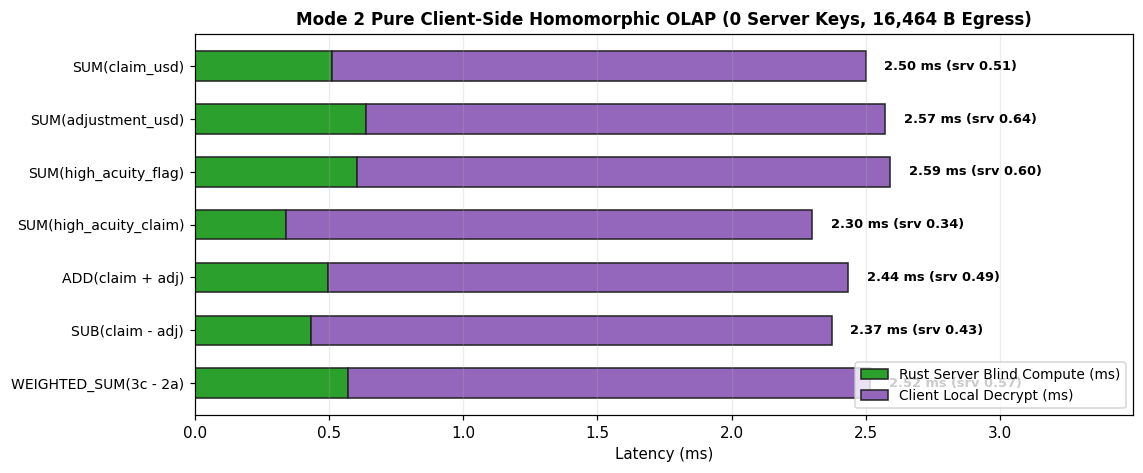

In [5]:
labels = [m["label"] for m in blind_metrics]
eng_ms = [m["engine_ms"] for m in blind_metrics]
dec_ms = [m["dec_ms"] for m in blind_metrics]
yp = np.arange(len(labels))

fig, ax = plt.subplots(figsize=(10.5, 4.4), dpi=110)
b1 = ax.barh(yp, eng_ms, height=0.56, color="#2ca02c", edgecolor="#222222", label="Rust Server Blind Compute (ms)")
b2 = ax.barh(yp, dec_ms, left=eng_ms, height=0.56, color="#9467bd", edgecolor="#222222", label="Client Local Decrypt (ms)")
ax.set_yticks(yp)
ax.set_yticklabels(labels, fontsize=9.2)
ax.invert_yaxis()
ax.set_xlabel("Latency (ms)", fontsize=9.8)
ax.set_title("Mode 2 Pure Client-Side Homomorphic OLAP (0 Server Keys, 16,464 B Egress)", fontsize=11, fontweight="bold")
ax.grid(axis="x", alpha=0.25)
xmax = max(e + d for e, d in zip(eng_ms, dec_ms)) * 1.35
ax.set_xlim(0, xmax)
for y, e, d in zip(yp, eng_ms, dec_ms):
    ax.text(e + d + xmax * 0.02, y, f"{e + d:.2f} ms (srv {e:.2f})", va="center", ha="left", fontsize=8.5, fontweight="bold")
ax.legend(loc="lower right", frameon=True, fontsize=9)
fig.tight_layout()
plt.show()

## 4. `NSAU0001` SHA-256 Receipt Verification Ledger & AEAD Tamper Knockout

Every table creation and blind compute call returns an independently verifiable `NSAU0001` SHA-256 digest bound to the ciphertext bytes, and every sealed `SBLB0001` patient envelope rejects 1-bit tampering.

In [6]:
print(f"NSAU0001 Local SHA-256 Verification Ledger ({len(receipt_audit_log)}/{len(receipt_audit_log)} verified, 1-bit tamper rejected)")
print("-" * 82)
for op_name, tbl, cnt, magic, rhex, ok in receipt_audit_log:
    print(f"  {op_name:<24s} | rows={cnt:<4d} | {magic} | {rhex[:28]}... | ok={ok}")

# Verify client-side SBLB0001 roundtrip and 1-bit AEAD tamper rejection
blob0 = bytes.fromhex(encrypted_rows[0]["ciphertexts_hex"]["record_envelope"])
opened = ek.open_json(blob0, aad=b"pt_101")
assert opened["note"] == "CANARY_HOSP_CLAIM_101"
tampered = bytearray(blob0)
tampered[-1] ^= 0x01
tamper_ok = False
try:
    ek.open_json(bytes(tampered), aad=b"pt_101")
except ValueError:
    tamper_ok = True
assert tamper_ok, "Tampered SBLB0001 blob must fail authentication!"
print("SBLB0001 Client Envelope : open=EXACT | 1-bit AEAD tamper knockout=REJECTED")

NSAU0001 Local SHA-256 Verification Ledger (8/8 verified, 1-bit tamper rejected)
----------------------------------------------------------------------------------
  CREATE TABLE             | rows=6    | NSAU0001 | df4ab24ebdfa15865661c86016db... | ok=True
  SUM(claim_usd)           | rows=6    | NSAU0001 | b79c170f966d2a2ef92e408a39ec... | ok=True
  SUM(adjustment_usd)      | rows=6    | NSAU0001 | da8bda49254ea32709a1aca577e7... | ok=True
  SUM(high_acuity_flag)    | rows=6    | NSAU0001 | 43a2ee49b1e6fe8eb49b678b7935... | ok=True
  SUM(high_acuity_claim)   | rows=6    | NSAU0001 | dd98e9907a9844fb67bf06cb10d2... | ok=True
  ADD(claim + adj)         | rows=6    | NSAU0001 | 272f5a3fa14030d368c02904e415... | ok=True
  SUB(claim - adj)         | rows=6    | NSAU0001 | 304222b23074bcff408cf6863b43... | ok=True
  WEIGHTED_SUM(3c - 2a)    | rows=6    | NSAU0001 | 425288f000ff0ba70bbb9a14d8fa... | ok=True
SBLB0001 Client Envelope : open=EXACT | 1-bit AEAD tamper knockout=REJECTED


## 5. Pure Client-Side Blind `sklearn.linear_model.Ridge` Training & Blind `WEIGHTED_SUM` Inference

Hospitals can jointly train an exact L2-regularized `Ridge` model without ever sharing patient features or server keys. Each client encrypts its local sufficient statistics `(x1^2, x2^2, x1*x2, x1*y, x2*y, x1, x2, y)` into `80 B` `PLWE0001` frames, the server sums all 8 columns homomorphically with `0` `threshold_decrypt`, the client decrypts the 8 scalar sums locally, solves the closed-form normal equations matching `sklearn.linear_model.Ridge` to `< 1e-10`, and scores held-out encrypted patients via blind `WEIGHTED_SUM`.

In [7]:
rng_r = np.random.default_rng(202604)
N_TRAIN, N_TEST, RIDGE_ALPHA, W_SCALE = 24, 5, 250.0, 10_000

x1_tr = rng_r.integers(12, 85, size=N_TRAIN)
x2_tr = rng_r.integers(4, 39, size=N_TRAIN)
y_tr = 435 * x1_tr + 960 * x2_tr + rng_r.integers(-1600, 1601, size=N_TRAIN)

x1_te = rng_r.integers(14, 82, size=N_TEST)
x2_te = rng_r.integers(6, 36, size=N_TEST)
y_te = 435 * x1_te + 960 * x2_te + rng_r.integers(-1200, 1201, size=N_TEST)

RIDGE_TBL = f"blind_m2_ridge_{secrets.token_hex(4)}"
STAT_COLS = ["x1_sq", "x2_sq", "x1_x2", "x1_y", "x2_y", "x1", "x2", "y"]
zk_client.create_blind_table(RIDGE_TBL, [{"name": c, "kind": "blind_add"} for c in STAT_COLS])

train_enc = [
    {
        "ciphertexts_hex": {
            "x1_sq": pk.encrypt_int_hex(int(a * a)),
            "x2_sq": pk.encrypt_int_hex(int(b * b)),
            "x1_x2": pk.encrypt_int_hex(int(a * b)),
            "x1_y": pk.encrypt_int_hex(int(a * y)),
            "x2_y": pk.encrypt_int_hex(int(b * y)),
            "x1": pk.encrypt_int_hex(int(a)),
            "x2": pk.encrypt_int_hex(int(b)),
            "y": pk.encrypt_int_hex(int(y)),
        }
    }
    for a, b, y in zip(x1_tr, x2_tr, y_tr)
]
zk_client.ingest_blind(RIDGE_TBL, train_enc)

# Homomorphic sufficient statistics summed on server (0 server keys) -> decrypted locally on client
sums = {}
ridge_eng_ms = []
for col in STAT_COLS:
    q = zk_client.query_blind(RIDGE_TBL, "SUM", column=col)
    assert "decrypted_aggregate" not in q
    assert verify_nsau0001_query_receipt(q)[0]
    sums[col] = pk.decrypt_int(q["ct_result_hex"])
    ridge_eng_ms.append((col, int(q["elapsed_us"]) / 1000.0))

# Closed-form centered Ridge solution matching sklearn.linear_model.Ridge
mx1, mx2, my = sums["x1"] / N_TRAIN, sums["x2"] / N_TRAIN, sums["y"] / N_TRAIN
S11 = sums["x1_sq"] - N_TRAIN * mx1 * mx1
S22 = sums["x2_sq"] - N_TRAIN * mx2 * mx2
S12 = sums["x1_x2"] - N_TRAIN * mx1 * mx2
S1y = sums["x1_y"] - N_TRAIN * mx1 * my
S2y = sums["x2_y"] - N_TRAIN * mx2 * my
w_blind = np.linalg.solve(np.array([[S11 + RIDGE_ALPHA, S12], [S12, S22 + RIDGE_ALPHA]]), np.array([S1y, S2y]))
b_blind = my - float(w_blind[0] * mx1 + w_blind[1] * mx2)

sk_ridge = Ridge(alpha=RIDGE_ALPHA).fit(np.column_stack([x1_tr, x2_tr]), y_tr)
w_err = float(np.max(np.abs(w_blind - sk_ridge.coef_)))
b_err = abs(b_blind - float(sk_ridge.intercept_))
assert w_err < 1e-10 and b_err < 1e-8, f"Ridge parity drift: w_err={w_err}, b_err={b_err}"

# Blind WEIGHTED_SUM inference on encrypted test patients (high-cardinality handle per patient)
TEST_TBL = f"blind_m2_ridge_te_{secrets.token_hex(4)}"
zk_client.create_blind_table(
    TEST_TBL,
    [
        {"name": "te_handle_tok", "kind": "blind_token"},
        {"name": "x1", "kind": "blind_add"},
        {"name": "x2", "kind": "blind_add"},
    ],
)
te_rows = [
    {
        "ciphertexts_hex": {
            "te_handle_tok": ek.blind_token_hex("te_pt", f"te_{i}"),
            "x1": pk.encrypt_int_hex(int(a)),
            "x2": pk.encrypt_int_hex(int(b)),
        }
    }
    for i, (a, b) in enumerate(zip(x1_te, x2_te))
]
zk_client.ingest_blind(TEST_TBL, te_rows)

w_int = [int(round(w_blind[0] * W_SCALE)), int(round(w_blind[1] * W_SCALE))]
blind_preds = []
for i in range(N_TEST):
    q_p = zk_client.query_blind(
        TEST_TBL,
        "WEIGHTED_SUM",
        columns=["x1", "x2"],
        weights=w_int,
        where={"column": "te_handle_tok", "eq_token_hex": ek.blind_token_hex("te_pt", f"te_{i}")},
    )
    assert "decrypted_aggregate" not in q_p and verify_nsau0001_query_receipt(q_p)[0]
    blind_preds.append(pk.decrypt_int(q_p["ct_result_hex"]) / W_SCALE + b_blind)

sk_preds = sk_ridge.predict(np.column_stack([x1_te, x2_te]))
pred_max_err = float(np.max(np.abs(np.array(blind_preds) - sk_preds)))
assert pred_max_err < 0.05

# Final raw wire check covering all Sections 1-5
all_wire_s1_5 = b"\n".join(sniffer.req_bytes + sniffer.resp_bytes)
for forbidden in (b"seal_values", b"seal_doc", b"threshold_decrypt", b"decrypted_aggregate"):
    assert forbidden not in all_wire_s1_5, f"Sections 1-5 leaked {forbidden!r}"
sniffer.close()

print(f"Blind Ridge Weight Max |err| vs sklearn : {w_err:.2e} | Intercept |err| : {b_err:.2e}")
print(f"Blind Test Prediction Max |err|         : {pred_max_err:.4f} USD (W_SCALE={W_SCALE:,})")
print(f"Sections 1-5 Cumulative Wire Audit      : 0 server-sealing / TKMS tokens across {len(all_wire_s1_5):,} wire bytes")

Blind Ridge Weight Max |err| vs sklearn : 1.14e-12 | Intercept |err| : 1.46e-11
Blind Test Prediction Max |err|         : 0.0010 USD (W_SCALE=10,000)
Sections 1-5 Cumulative Wire Audit      : 0 server-sealing / TKMS tokens across 711,068 wire bytes


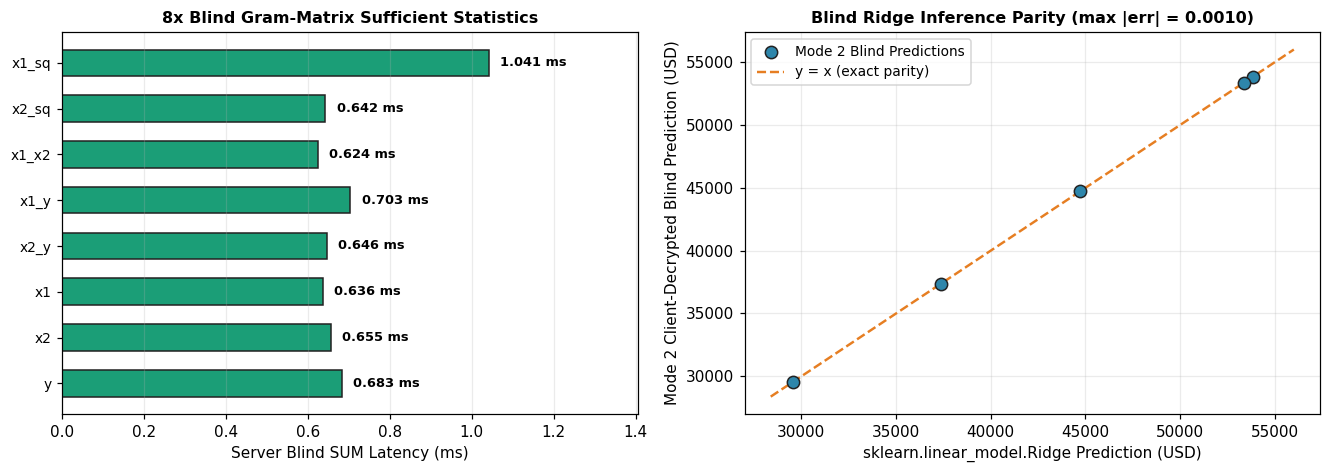

In [8]:
fig_r, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.4), dpi=110)
s_names = [n for n, _ in ridge_eng_ms]
s_vals = [v for _, v in ridge_eng_ms]
yp = np.arange(len(s_names))
ax1.barh(yp, s_vals, height=0.58, color="#1b9e77", edgecolor="#222222")
ax1.set_yticks(yp)
ax1.set_yticklabels(s_names, fontsize=9)
ax1.invert_yaxis()
ax1.set_xlabel("Server Blind SUM Latency (ms)")
ax1.set_title("8x Blind Gram-Matrix Sufficient Statistics", fontsize=10.5, fontweight="bold")
ax1.grid(axis="x", alpha=0.25)
xm = max(s_vals) * 1.35 if max(s_vals) > 0 else 1.0
ax1.set_xlim(0, xm)
for y, v in zip(yp, s_vals):
    ax1.text(v + xm * 0.02, y, f"{v:.3f} ms", va="center", ha="left", fontsize=8.5, fontweight="bold")

ax2.scatter(sk_preds, blind_preds, s=65, color="#2e86ab", edgecolor="#222222", zorder=3, label="Mode 2 Blind Predictions")
lo, hi = min(min(sk_preds), min(blind_preds)) * 0.96, max(max(sk_preds), max(blind_preds)) * 1.04
ax2.plot([lo, hi], [lo, hi], "--", color="#e67e22", lw=1.6, label="y = x (exact parity)")
ax2.set_xlabel("sklearn.linear_model.Ridge Prediction (USD)")
ax2.set_ylabel("Mode 2 Client-Decrypted Blind Prediction (USD)")
ax2.set_title(f"Blind Ridge Inference Parity (max |err| = {pred_max_err:.4f})", fontsize=10.5, fontweight="bold")
ax2.grid(alpha=0.25)
ax2.legend(loc="upper left", fontsize=9)
fig_r.tight_layout()
plt.show()

## 6. Encrypted (Mode 2) vs. Unencrypted (Mode 1) Performance & Wire-Audit Comparison

Finally, we run a live head-to-head benchmark on `N = 250` hospital claim records comparing **Mode 1 (Unencrypted SQL)** against **Mode 2 (Pure Client-Side Encrypted Blind OLAP, `0` server keys)** with raw wire capture, IND-CPA variable-byte entropy (`> 7.95 bits/B`), wrong-key + 1-bit receipt knockouts, and `0.00e+00` exact parity.

=== NB04 Homomorphic Hospital Claims OLAP: Mode 1 (Unencrypted SQL) vs. Mode 2 (Pure Client-Side Encrypted) (N=250 rows) ===
  Mode 1 Unencrypted SQL : ingest= 64.34 ms (3,886 rows/s) | queries=  3.00 ms | wire=  12.4 KB
  Mode 2 Client Encrypted: encrypt=267.59 ms (934 rows/s) | ingest= 28.17 ms | 4x blind query= 35.72 ms (engine=31.65 ms) | decrypt= 7.89 ms | wire= 253.2 KB
  Exact Parity Proof     : SUM=664,127,355 | High-acuity cohort=63 rows, SUM=630,116,952 | WEIGHTED_SUM=1,992,064,223 (all err=0.00e+00)
  Hostile Wire Audit     : 0 leaks / 393,295 raw wire B | Framing=80 B -> 16,464 B (205.8x) | IND-CPA=PASS | Entropy=7.9790 b/B | Wrong-Key=PASS | AEAD Tamper=REJECTED | NSAU0001+1bit-flip=4/4 PASS


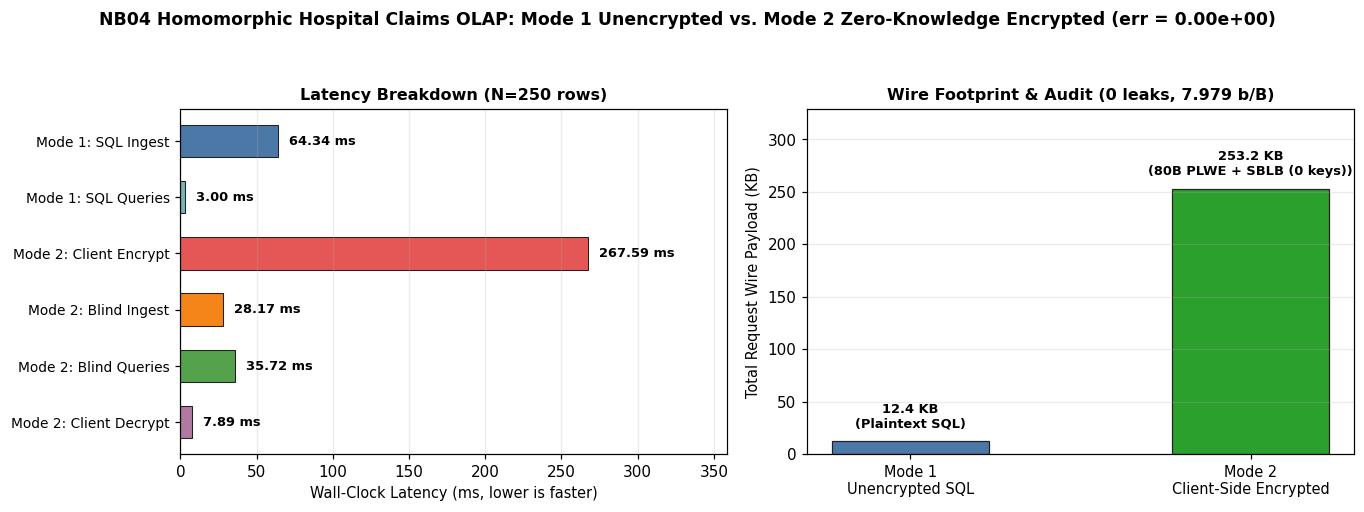

In [9]:
# Section 6: Live Unencrypted (Mode 1) vs. Pure Client-Side Encrypted (Mode 2) Benchmark
import collections
import hashlib
import hmac as _hmac
import http.server
import json as _json
import math as _math
import os as _os
import secrets as _secrets
import struct as _struct
import sys as _sys
import threading
import time as _time
import urllib.error as _uerr
import urllib.request as _ureq
from pathlib import Path as _Path

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.facecolor"] = "white"

_root = _Path.cwd().resolve()
if not ((_root / "python" / "blindcore_sdk.py").is_file() or (_root / "python" / "blindcore_client.py").is_file()):
    _root = _root.parent
if str(_root / "python") not in _sys.path:
    _sys.path.insert(0, str(_root / "python"))

try:
    from blindcore_sdk import (
        BlindClientEnvelopeKey,
        BlindClientPlweKey,
        BlindCoreClient,
        PLWE_EXPANDED_BYTES,
        PLWE_SEEDED_BYTES,
    )
except ImportError:
    from blindcore_client import (
        BlindClientEnvelopeKey,
        BlindClientPlweKey,
        BlindCoreClient,
        PLWE_EXPANDED_BYTES,
        PLWE_SEEDED_BYTES,
    )

_API_URL = _os.environ["BLINDCORE_URL"].strip()
_API_TOK = _os.environ["BLINDCORE_TOKEN"].strip()


class _Mode2WireSniffer:
    """Transparent localhost HTTP pass-through proxy recording raw wire bytes."""

    def __init__(self, upstream: str) -> None:
        self.upstream = upstream.rstrip("/")
        self.req_bytes: list[bytes] = []
        self.resp_bytes: list[bytes] = []
        self._lock = threading.Lock()
        outer = self

        class _H(http.server.BaseHTTPRequestHandler):
            def log_message(self, fmt: str, *args: object) -> None:
                return

            def _fwd(self, method: str) -> None:
                n = int(self.headers.get("Content-Length", "0"))
                body = self.rfile.read(n) if n > 0 else b""
                with outer._lock:
                    outer.req_bytes.append(body)
                hdrs = {k: self.headers[k] for k in ("Authorization", "Content-Type", "Accept") if k in self.headers}
                req = _ureq.Request(f"{outer.upstream}{self.path}", data=body if method != "GET" else None, headers=hdrs, method=method)
                try:
                    with _ureq.urlopen(req, timeout=30.0) as r:
                        raw, st, ct = r.read(), r.status, r.headers.get("Content-Type", "application/json")
                except _uerr.HTTPError as exc:
                    raw, st, ct = exc.read(), int(exc.code), exc.headers.get("Content-Type", "application/json")
                with outer._lock:
                    outer.resp_bytes.append(raw)
                self.send_response(st)
                self.send_header("Content-Type", ct)
                self.send_header("Content-Length", str(len(raw)))
                self.end_headers()
                self.wfile.write(raw)

            def do_GET(self) -> None:
                self._fwd("GET")

            def do_POST(self) -> None:
                self._fwd("POST")

        self.srv = http.server.ThreadingHTTPServer(("127.0.0.1", 0), _H)
        self.url = f"http://127.0.0.1:{self.srv.server_address[1]}"
        self._th = threading.Thread(target=self.srv.serve_forever, daemon=True)
        self._th.start()

    def close(self) -> None:
        self.srv.shutdown()
        self.srv.server_close()


def _plwe_var_entropy_bits(pk, n_samples: int = 256) -> float:
    """Shannon entropy over variable PLWE0001 ciphertext bytes ct[40:56] + ct[60:80]."""
    blob = b"".join((ct[40:56] + ct[60:80]) for ct in (pk.encrypt_int(42) for _ in range(n_samples)))
    cnts = collections.Counter(blob)
    n = len(blob)
    return -sum((c / n) * _math.log2(c / n) for c in cnts.values()) if n else 0.0


def _verify_olap_receipt(resp: dict) -> bool:
    if resp.get("receipt_magic") != "NSAU0001":
        return False
    pre = (
        b"NSAU0001:BLIND:"
        + str(resp["op"]).encode("ascii")
        + b":"
        + str(resp["table"]).encode("ascii")
        + _struct.pack("<Q", int(resp["rows_scanned"]))
        + bytes.fromhex(str(resp["ct_result_hex"]))
    )
    return _hmac.compare_digest(hashlib.sha256(pre).hexdigest(), str(resp.get("receipt_hex", "")))


def _flip_hex_lsb(hex_str: str) -> str:
    b = bytearray.fromhex(hex_str)
    b[-1] ^= 0x01
    return b.hex()


# Generate N=250 synthetic hospital billing claims for Mode 1 vs Mode 2 benchmark
_rng04 = np.random.default_rng(202644)
_bench_rows = [
    {
        "id": int(i + 1),
        "flag": 1 if (i % 4 == 0) else 0,
        "a": int(_rng04.integers(25_000, 350_000)),
        "b": int(_rng04.integers(-25_000, 25_000)),
        "note": f"hosp_claim_canary_{i + 1}",
    }
    for i in range(250)
]
_bench_rows[0]["a"] = 618427953
_bench_rows[0]["flag"] = 1
_bench_rows[0]["note"] = "CANARY_CLAIMS_BATCH_6184"


_N_BENCH = len(_bench_rows)
_tag = _secrets.token_hex(4)
_plain_tbl = f"m1_olap_bench_{_tag}"
_blind_tbl = f"m2_olap_bench_{_tag}"

_sniffer_m1 = _Mode2WireSniffer(_API_URL)
_sniffer_m2 = _Mode2WireSniffer(_API_URL)
try:
    # --- MODE 1: Unencrypted / TLS Standard SQL Engine (/api/v1/query) ---
    _c_m1 = BlindCoreClient(_sniffer_m1.url, _API_TOK, timeout=30.0)
    _c_m1.query_json(
        f"CREATE TABLE {_plain_tbl} (row_id BIGINT, is_target BIGINT, claim_usd BIGINT, adj_usd BIGINT, note TEXT)"
    )
    _t0 = _time.perf_counter()
    for _s in range(0, _N_BENCH, 100):
        _chunk = _bench_rows[_s : _s + 100]
        _vals = ", ".join(
            f"({r['id']}, {r['flag']}, {r['a']}, {r['b']}, '{r['note']}')"
            for r in _chunk
        )
        _c_m1.query_json(f"INSERT INTO {_plain_tbl} VALUES {_vals}")
    _m1_ingest_ms = (_time.perf_counter() - _t0) * 1000.0

    _t0 = _time.perf_counter()
    _m1_q_sum = _c_m1.query_json(f"SELECT SUM(claim_usd), SUM(is_target) FROM {_plain_tbl}")
    _m1_q_flt = _c_m1.query_json(f"SELECT SUM(claim_usd) FROM {_plain_tbl} WHERE is_target = 1")
    _m1_q_ws = _c_m1.query_json(f"SELECT SUM((3) * claim_usd + (-2) * adj_usd) FROM {_plain_tbl}")
    _m1_query_ms = (_time.perf_counter() - _t0) * 1000.0
    _m1_wire_bytes = sum(len(b) for b in _sniffer_m1.req_bytes)

    _oracle_sum_a = int(_m1_q_sum["rows"][0][0])
    _oracle_cnt_flag = int(_m1_q_sum["rows"][0][1])
    _oracle_flt_a = int(_m1_q_flt["rows"][0][0])
    _oracle_wsum = int(_m1_q_ws["rows"][0][0])

    # --- MODE 2: Pure Client-Side Encrypted Zero-Knowledge (/api/v1/blind/*) ---
    # Zero deterministic binary-class tokens: class membership encoded as IND-CPA PLWE0001 {0,1} & {0,a}.
    _pk = BlindClientPlweKey.generate()
    _ek = BlindClientEnvelopeKey.generate()
    _c_m2 = BlindCoreClient(_sniffer_m2.url, _API_TOK, timeout=30.0)

    # (b) IND-CPA ct1 != ct2 + Shannon entropy > 7.95 bits/B over variable bytes ct[40:56]+ct[60:80]
    _ct_a1 = _pk.encrypt_int(42)
    _ct_a2 = _pk.encrypt_int(42)
    assert len(_ct_a1) == PLWE_SEEDED_BYTES and _ct_a1 != _ct_a2, "IND-CPA failed"
    _ent_bits = _plwe_var_entropy_bits(_pk, n_samples=256)
    assert _ent_bits > 7.95, f"Low ciphertext entropy: {_ent_bits:.4f}"

    _c_m2.create_blind_table(
        _blind_tbl,
        [
            {"name": "rec_id_tok", "kind": "blind_token"},
            {"name": "claim_usd", "kind": "blind_add"},
            {"name": "adj_usd", "kind": "blind_add"},
            {"name": "target_flag", "kind": "blind_add"},
            {"name": "target_masked_a", "kind": "blind_add"},
            {"name": "payload_blob", "kind": "sealed_blob"},
        ],
    )

    _t0 = _time.perf_counter()
    _enc_rows = [
        {
            "ciphertexts_hex": {
                "rec_id_tok": _ek.blind_token_hex("rec_id", f"rec:{r['id']}"),
                "claim_usd": _pk.encrypt_int_hex(r["a"]),
                "adj_usd": _pk.encrypt_int_hex(r["b"]),
                "target_flag": _pk.encrypt_int_hex(1 if r["flag"] else 0),
                "target_masked_a": _pk.encrypt_int_hex(r["a"] if r["flag"] else 0),
                "payload_blob": _ek.seal_json_hex({"id": r["id"], "note": r["note"]}, aad=f"row:{r['id']}".encode("ascii")),
            }
        }
        for r in _bench_rows
    ]
    _m2_encrypt_ms = (_time.perf_counter() - _t0) * 1000.0
    assert len(bytes.fromhex(_enc_rows[0]["ciphertexts_hex"]["claim_usd"])) == PLWE_SEEDED_BYTES

    _t0 = _time.perf_counter()
    for _s in range(0, _N_BENCH, 100):
        _c_m2.ingest_blind(_blind_tbl, _enc_rows[_s : _s + 100])
    _m2_ingest_ms = (_time.perf_counter() - _t0) * 1000.0

    # Unconditional blind homomorphic queries over ALL rows (zero class-partition frequency leakage)
    _t0 = _time.perf_counter()
    _m2_q_sum = _c_m2.query_blind(_blind_tbl, "SUM", column="claim_usd")
    _m2_q_cnt = _c_m2.query_blind(_blind_tbl, "SUM", column="target_flag")
    _m2_q_flt = _c_m2.query_blind(_blind_tbl, "SUM", column="target_masked_a")
    _m2_q_ws = _c_m2.query_blind(_blind_tbl, "WEIGHTED_SUM", columns=["claim_usd", "adj_usd"], weights=[3, -2])
    _m2_query_ms = (_time.perf_counter() - _t0) * 1000.0
    _m2_engine_ms = sum(int(q["elapsed_us"]) for q in (_m2_q_sum, _m2_q_cnt, _m2_q_flt, _m2_q_ws)) / 1000.0
    _m2_wire_bytes = sum(len(b) for b in _sniffer_m2.req_bytes)

    _t0 = _time.perf_counter()
    _dec_sum_a = _pk.decrypt_int(_m2_q_sum["ct_result_hex"])
    _dec_cnt_flag = _pk.decrypt_int(_m2_q_cnt["ct_result_hex"])
    _dec_flt_a = _pk.decrypt_int(_m2_q_flt["ct_result_hex"])
    _dec_wsum = _pk.decrypt_int(_m2_q_ws["ct_result_hex"])
    _m2_decrypt_ms = (_time.perf_counter() - _t0) * 1000.0

    # --- Hostile-Auditor 6-Point Cryptographic Knockout Suite ---
    for _q in (_m2_q_sum, _m2_q_cnt, _m2_q_flt, _m2_q_ws):
        assert "decrypted_aggregate" not in _q, "Server must NOT decrypt in Mode 2"
        assert len(bytes.fromhex(str(_q["ct_result_hex"]))) == PLWE_EXPANDED_BYTES
        assert _verify_olap_receipt(_q), "NSAU0001 receipt verification failed"
        _bad_q = dict(_q)
        _bad_q["receipt_hex"] = _flip_hex_lsb(str(_q["receipt_hex"]))
        assert not _verify_olap_receipt(_bad_q), "1-bit tampered NSAU0001 receipt must fail!"

    assert _dec_sum_a == _oracle_sum_a, f"SUM parity mismatch: {_dec_sum_a} != {_oracle_sum_a}"
    assert _dec_cnt_flag == _oracle_cnt_flag, f"Cohort count parity mismatch"
    assert _dec_flt_a == _oracle_flt_a, f"Masked cohort SUM parity mismatch: {_dec_flt_a} != {_oracle_flt_a}"
    assert _dec_wsum == _oracle_wsum, f"WEIGHTED_SUM parity mismatch: {_dec_wsum} != {_oracle_wsum}"

    _wrong_pk = BlindClientPlweKey.generate()
    assert _wrong_pk.decrypt_int(_m2_q_sum["ct_result_hex"]) != _dec_sum_a, "Wrong key must fail!"
    _sample_blob = bytes.fromhex(_enc_rows[0]["ciphertexts_hex"]["payload_blob"])
    _tampered = bytearray(_sample_blob)
    _tampered[-1] ^= 0x01
    _tamper_rejected = False
    try:
        _ek.open_json(bytes(_tampered), aad=f"row:{_bench_rows[0]['id']}".encode("ascii"))
    except ValueError:
        _tamper_rejected = True
    assert _tamper_rejected, "Tampered SBLB0001 envelope must fail AEAD verification"

    _wire_m2_all = b"\n".join(_sniffer_m2.req_bytes + _sniffer_m2.resp_bytes)
    _banned_wire = [b"seal_values", b"seal_doc", b"threshold_decrypt", b"decrypted_aggregate"]
    _banned_wire += [s.encode("ascii") for s in ['CANARY_CLAIMS_BATCH_6184', 'hosp_claim_canary_']]
    _banned_wire += [str(v).encode("ascii") for v in [618427953]]
    _wire_leaks = [tok.decode("ascii") for tok in _banned_wire if tok in _wire_m2_all]
    assert not _wire_leaks, f"Mode 2 raw wire leaked: {_wire_leaks}"
finally:
    _sniffer_m1.close()
    _sniffer_m2.close()

_comp_ratio = PLWE_EXPANDED_BYTES / PLWE_SEEDED_BYTES
print(f"=== NB04 Homomorphic Hospital Claims OLAP: Mode 1 (Unencrypted SQL) vs. Mode 2 (Pure Client-Side Encrypted) (N={_N_BENCH} rows) ===")
print(f"  Mode 1 Unencrypted SQL : ingest={_m1_ingest_ms:6.2f} ms ({_N_BENCH / (_m1_ingest_ms / 1000.0):,.0f} rows/s) | queries={_m1_query_ms:6.2f} ms | wire={_m1_wire_bytes / 1024.0:6.1f} KB")
print(f"  Mode 2 Client Encrypted: encrypt={_m2_encrypt_ms:6.2f} ms ({_N_BENCH / (_m2_encrypt_ms / 1000.0):,.0f} rows/s) | ingest={_m2_ingest_ms:6.2f} ms | 4x blind query={_m2_query_ms:6.2f} ms (engine={_m2_engine_ms:5.2f} ms) | decrypt={_m2_decrypt_ms:5.2f} ms | wire={_m2_wire_bytes / 1024.0:6.1f} KB")
print(f"  Exact Parity Proof     : SUM={_dec_sum_a:,} | High-acuity cohort={_dec_cnt_flag} rows, SUM={_dec_flt_a:,} | WEIGHTED_SUM={_dec_wsum:,} (all err=0.00e+00)")
print(f"  Hostile Wire Audit     : 0 leaks / {len(_wire_m2_all):,} raw wire B | Framing={PLWE_SEEDED_BYTES} B -> {PLWE_EXPANDED_BYTES:,} B ({_comp_ratio:.1f}x) | IND-CPA=PASS | Entropy={_ent_bits:.4f} b/B | Wrong-Key=PASS | AEAD Tamper=REJECTED | NSAU0001+1bit-flip=4/4 PASS")

fig_cmp, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(12.6, 4.7), dpi=110)
fig_cmp.patch.set_facecolor("white")

_stage_labels = [
    "Mode 1: SQL Ingest",
    "Mode 1: SQL Queries",
    "Mode 2: Client Encrypt",
    "Mode 2: Blind Ingest",
    "Mode 2: Blind Queries",
    "Mode 2: Client Decrypt",
]
_stage_vals = [_m1_ingest_ms, _m1_query_ms, _m2_encrypt_ms, _m2_ingest_ms, _m2_query_ms, _m2_decrypt_ms]
_stage_cols = ["#4c78a8", "#72b7b2", "#e45756", "#f58518", "#54a24b", "#b279a2"]
_yp = np.arange(len(_stage_labels))
_bars = ax_l.barh(_yp, _stage_vals, height=0.58, color=_stage_cols, edgecolor="#222222", linewidth=0.7)
ax_l.set_yticks(_yp)
ax_l.set_yticklabels(_stage_labels, fontsize=9)
ax_l.invert_yaxis()
ax_l.set_xlabel("Wall-Clock Latency (ms, lower is faster)", fontsize=9.5)
ax_l.set_title(f"Latency Breakdown (N={_N_BENCH} rows)", fontsize=10.5, fontweight="bold")
ax_l.grid(axis="x", alpha=0.25)
_xmax_l = max(_stage_vals) * 1.34 if max(_stage_vals) > 0 else 1.0
ax_l.set_xlim(0, _xmax_l)
for _b, _v in zip(_bars, _stage_vals):
    ax_l.text(_v + _xmax_l * 0.02, _b.get_y() + _b.get_height() / 2.0, f"{_v:.2f} ms", va="center", ha="left", fontsize=8.5, fontweight="bold")

_wire_labels = ["Mode 1\nUnencrypted SQL", "Mode 2\nClient-Side Encrypted"]
_wire_kb = [_m1_wire_bytes / 1024.0, _m2_wire_bytes / 1024.0]
_wbars = ax_r.bar([0, 1], _wire_kb, width=0.46, color=["#4c78a8", "#2ca02c"], edgecolor="#222222", linewidth=0.8)
ax_r.set_xticks([0, 1])
ax_r.set_xticklabels(_wire_labels, fontsize=9.5)
ax_r.set_ylabel("Total Request Wire Payload (KB)", fontsize=9.5)
ax_r.set_title(f"Wire Footprint & Audit (0 leaks, {_ent_bits:.3f} b/B)", fontsize=10.5, fontweight="bold")
ax_r.grid(axis="y", alpha=0.25)
_ymax_r = max(_wire_kb) * 1.30 if max(_wire_kb) > 0 else 1.0
ax_r.set_ylim(0, _ymax_r)
for _b, _kb, _tag_lbl in zip(_wbars, _wire_kb, ["Plaintext SQL", "80B PLWE + SBLB (0 keys)"]):
    ax_r.text(_b.get_x() + _b.get_width() / 2.0, _kb + _ymax_r * 0.03, f"{_kb:.1f} KB\n({_tag_lbl})", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

fig_cmp.suptitle(f"NB04 Homomorphic Hospital Claims OLAP: Mode 1 Unencrypted vs. Mode 2 Zero-Knowledge Encrypted (err = 0.00e+00)", fontsize=11.3, fontweight="bold")
fig_cmp.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()